# Start with provenance and a study-area profile

**Objective:** Trace an observation to its source, distinguish spatial support, and make a reproducible study-area summary.

Original project lesson. All observations are real USGS Landsat / U.S. Census inputs, with source details in `data/manifest.json`. No health outcome is inferred.

A profile begins with a bounded question rather than a score. This real Fresno snapshot joins USGS Landsat observations from **30 August 2024** to **2020 Census** tract counts. The two dates do not match. Our satellite table is a systematic sample of actual native product pixels, not a census of every pixel. Display tiles mark sampling spacing and do not enlarge the physical observation footprint.

The manifest records source identifiers, transformations, units and provenance. SHA-256 file verification is performed by the repository data check. Browser filesystems may reserialize JSON, so this lesson checks scientific values rather than raw JSON bytes.

[Run this exact lesson in the browser Python Lab](https://jltobias.github.io/JupyterLite-OneHealth/lite/lab/index.html?path=00_provenance_profile.ipynb).

## Load the real bundled evidence

Run cells in order. In JupyterLite, the first run may download Python and Matplotlib and requires internet access. Wait for the kernel to finish. Files are in browser storage: use **File → Save and Export Notebook As** or right-click a file and **Download** to keep work outside this browser. Desktop execution uses the pinned build environment.

In [1]:
import sys, csv, json, math, statistics
from pathlib import Path
if sys.platform == "emscripten":
    import piplite
    await piplite.install("matplotlib")
import matplotlib.pyplot as plt
get_ipython().run_line_magic("matplotlib", "inline")
manifest = json.loads(Path("data/manifest.json").read_text())
with Path("data/pixels.csv").open() as f:
    rows = list(csv.DictReader(f))
text_fields = {"id"}
data = [{k: (v if k in text_fields else float(v) if v else None)
         for k, v in row.items()} for row in rows]
tracts = json.loads(Path("data/tracts.geojson").read_text())["features"]
def values(key, source=data):
    return [r[key] for r in source if r[key] is not None and math.isfinite(r[key])]
def avg(key, source=data):
    a = values(key, source)
    return statistics.mean(a) if a else None
plt.rcParams.update({"figure.figsize": (8, 4), "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})
print(manifest["scene_id"], manifest["satellite_datetime"])
print("Real satellite samples:", len(data), "| population reference:", manifest["population_date"])


LC09_L2SP_042035_20240830_02_T1 2024-08-30T18:33:53.353894Z
Real satellite samples: 6890 | population reference: 2020-04-01


## Inspect the calculation

The following code keeps source units and dates explicit. Edit assumptions only after recording what changes.

In [2]:
assert manifest["scene_id"] == "LC09_L2SP_042035_20240830_02_T1"
assert manifest["source_crs"] == "EPSG:32611"
assert all(-180 <= r["lon"] <= 180 and -90 <= r["lat"] <= 90 for r in data)
print("Bounds [west, south, east, north]:", manifest["bbox"])
print("Sample spacing (m):", manifest["sample_spacing_m"])
print("Mean sampled NDVI:", round(avg("ndvi"), 4))
print("Mean sampled surface temperature (°C):", round(avg("temperature_c"), 2))

Bounds [west, south, east, north]: [-119.9, 36.65, -119.65, 36.9]
Sample spacing (m): 300
Mean sampled NDVI: 0.3153
Mean sampled surface temperature (°C): 43.57


## Make a figure from the observations

The figure describes the selected real evidence. It does not establish personal exposure or a causal health effect.

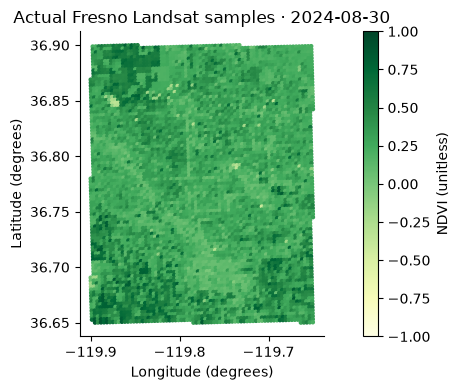

In [3]:
plt.scatter(values("lon"), values("lat"), c=[r["ndvi"] for r in data], s=5, cmap="YlGn", vmin=-1, vmax=1)
plt.colorbar(label="NDVI (unitless)")
plt.gca().set_aspect(1 / math.cos(math.radians(36.775)))
plt.xlabel("Longitude (degrees)"); plt.ylabel("Latitude (degrees)")
plt.title("Actual Fresno Landsat samples · 2024-08-30")
plt.tight_layout(); plt.show()

## Interpret and extend

Change the question from vegetation to human heat exposure. List three additional observations needed before this satellite map can answer it. Explain why the 2020 population count cannot resolve the time mismatch.

## Sources and attribution

- [USGS EROS, Landsat Collection 2 Level-2 science products; dataset DOI 10.5066/P9OGBGM6](https://www.usgs.gov/landsat-missions/landsat-collection-2-level-2-science-products).
- [U.S. Census Bureau, Census2020 TIGERweb Census Tracts layer 6 and POP100](https://tigerweb.geo.census.gov/arcgis/rest/services/Census2020/tigerWMS_Census2020/MapServer/6).

Data: USGS/NASA Landsat 8–9 Collection 2 Level-2, public domain; U.S. Census Bureau 2020 Census tracts and population, public domain. Accessed/acquired 7 November 2026. External readings are linked only; their prose, photographs, figures and code are not reproduced. Source organizations do not endorse this lesson.